# Hotel Booking Revenue & Occupancy Analytics
## Notebook 01: Data Quality & Exploratory Data Analysis (EDA)

---

### Purpose
This notebook performs exploratory analysis on the cleaned hotel booking dataset (`data/processed/bookings_clean.csv`). It validates data quality, investigates cancellation behavior across properties and lead times, analyzes seasonal volume and rate patterns, and tests sensitivity to duplicate bookings.

---

### Assumptions & Decision Framework (PROJECT_CONTEXT.md)
> **Authoritative Cleaning Decisions (D1–D12)**
> - **D1**: `booking_id` established as 1-based sequential integer (primary key).
> - **D2**: `arrival_date` derived from year, month name, and day without locale dependence.
> - **D3**: Missing values: `children` $\rightarrow$ 0, `country` $\rightarrow$ `'Unknown'`, `agent` kept as nullable `Int64`, `company` dropped (94.3% missing).
> - **D4**: Metrics: $\text{total\_nights} = \text{weekend} + \text{week nights}$; $\text{total\_guests} = \text{adults} + \text{children} + \text{babies}$; $\text{checkout\_date} = \text{arrival} + \text{total\_nights}$; $\text{booking\_date} = \text{arrival} - \text{lead\_time}$; $\text{room\_revenue} = \text{adr} \times \text{total\_nights}$.
> - **D5**: ADR Outliers: Exactly 2 rows with $\text{adr} < 0$ or $\text{adr} > 1000$ excluded to `data/processed/excluded_rows.csv`.
> - **D6**: Zero nights/guests: Flagged with `flag_zero_nights` and `flag_zero_guests` (count as bookings, contribute 0 room-nights).
> - **D7**: Duplicates: 31,994 identical raw rows flagged with `is_duplicate_row` (retained for sensitivity analysis).
> - **D8**: `reservation_status`: `'Check-Out'`, `'Canceled'`, `'No-Show'`. `is_canceled = 1` includes both Canceled and No-Show.
> - **D9**: `lead_bucket`: `'0-7'`, `'8-30'`, `'31-90'`, `'91-180'`, `'181+'` with orders 1 through 5.
> - **D10**: `room_type_mismatch = 1` when assigned room differs from reserved room.
> - **D11**: `days_cancelled_before_arrival = arrival_date - reservation_status_date` for Canceled reservations only; NULL otherwise.
> - **D12**: All boolean/flag columns stored as 0/1 integers.

> **KPI Definitions (K1–K7)**
> - **K1**: Room-night sold = non-cancelled booking $\times$ nights stayed.
> - **K2**: Room revenue = sum of ADR over room-nights sold.
> - **K3**: $\text{ADR} = \text{room revenue} / \text{room-nights sold}$ (never average ADR directly).
> - **K4**: $\text{Occupancy \%} = \text{room-nights sold} / \text{room-nights available}$; $\text{RevPAR} = \text{ADR} \times \text{Occupancy}$.
> - **K5**: Cancellation rate = canceled bookings / total bookings (attributed to arrival month).
> - **K6**: Stay conversion proxy = check-out bookings / total bookings ($1 - \text{cancellation rate}$). No website funnel data exists.
> - **K7**: Occupancy and RevPAR exist strictly at hotel level. Sliced views use revenue share and room-night share.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set global plotting style and coherent color palette
sns.set_theme(style="whitegrid", font="sans-serif")
HOTEL_PALETTE = {"City Hotel": "#1B365D", "Resort Hotel": "#D96B27"}
PRIMARY_COLOR = "#1B365D"
SECONDARY_COLOR = "#D96B27"
ACCENT_COLOR = "#2E8B57"

# File paths
raw_path = Path("../data/raw/hotel_bookings.csv")
clean_path = Path("../data/processed/bookings_clean.csv")
excl_path = Path("../data/processed/excluded_rows.csv")

# Load datasets
df_raw = pd.read_csv(raw_path)
df = pd.read_csv(clean_path, low_memory=False)
df_excl = pd.read_csv(excl_path, low_memory=False)

# Compile Data Quality Summary
n_raw = len(df_raw)
n_excl = len(df_excl)
n_clean = len(df)
n_zero_nights = int(df["flag_zero_nights"].sum())
n_zero_guests = int(df["flag_zero_guests"].sum())
n_dups = int(df["is_duplicate_row"].sum())

dq_summary = pd.DataFrame([
    {"Metric": "Raw Bookings Ingested", "Count": n_raw, "Percent of Raw": 100.0, "Disposition": "Source CSV read-only"},
    {"Metric": "ADR Outliers Excluded (D5)", "Count": n_excl, "Percent of Raw": round(n_excl / n_raw * 100, 4), "Disposition": "Saved to excluded_rows.csv"},
    {"Metric": "Clean Analytical Bookings", "Count": n_clean, "Percent of Raw": round(n_clean / n_raw * 100, 4), "Disposition": "Saved to bookings_clean.csv"},
    {"Metric": "Flagged Zero-Night Bookings (D6)", "Count": n_zero_nights, "Percent of Raw": round(n_zero_nights / n_clean * 100, 2), "Disposition": "flag_zero_nights = 1"},
    {"Metric": "Flagged Zero-Guest Bookings (D6)", "Count": n_zero_guests, "Percent of Raw": round(n_zero_guests / n_clean * 100, 2), "Disposition": "flag_zero_guests = 1"},
    {"Metric": "Flagged Exact Duplicate Rows (D7)", "Count": n_dups, "Percent of Raw": round(n_dups / n_clean * 100, 2), "Disposition": "is_duplicate_row = 1"}
])

print("=======================================================================")
print("DATA QUALITY & PIPELINE INGESTION SUMMARY")
print("=======================================================================")
print(dq_summary.to_string(index=False))


DATA QUALITY & PIPELINE INGESTION SUMMARY
                           Metric  Count  Percent of Raw                 Disposition
            Raw Bookings Ingested 119390        100.0000        Source CSV read-only
       ADR Outliers Excluded (D5)      2          0.0017  Saved to excluded_rows.csv
        Clean Analytical Bookings 119388         99.9983 Saved to bookings_clean.csv
 Flagged Zero-Night Bookings (D6)    715          0.6000        flag_zero_nights = 1
 Flagged Zero-Guest Bookings (D6)    180          0.1500        flag_zero_guests = 1
Flagged Exact Duplicate Rows (D7)  31994         26.8000        is_duplicate_row = 1


findfont: Failed to find font weight semibold for Arial, now using 700.


Saved: ../reports/figures/fig01_cancellation_rate_by_hotel.png


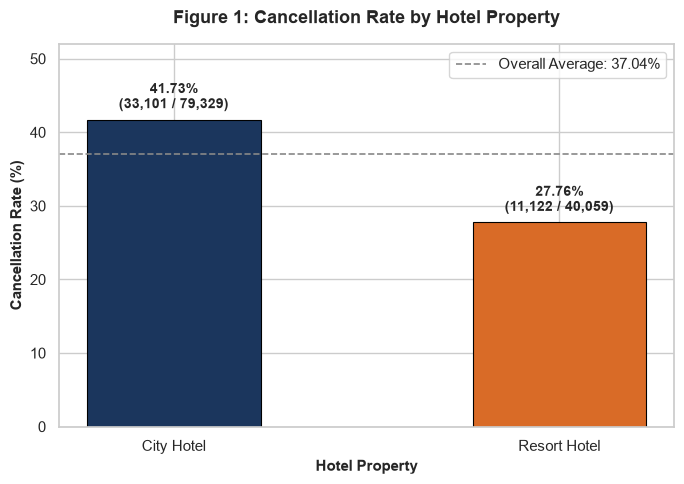

City Hotel: Cancellation Rate = 41.73% (33,101 / 79,329)
Resort Hotel: Cancellation Rate = 27.76% (11,122 / 40,059)
Overall Cancellation Rate = 37.04%


In [2]:
# Figure 1: Cancellation Rate by Hotel
fig, ax = plt.subplots(figsize=(7, 5))

hotel_cr = df.groupby("hotel")["is_canceled"].agg(
    rate=lambda x: x.mean() * 100,
    total="count",
    canceled="sum"
).reset_index()

overall_cr = df["is_canceled"].mean() * 100

bars = ax.bar(
    hotel_cr["hotel"],
    hotel_cr["rate"],
    color=[HOTEL_PALETTE[h] for h in hotel_cr["hotel"]],
    width=0.45,
    edgecolor="black",
    linewidth=0.8
)

# Benchmark line for overall dataset cancellation rate
ax.axhline(
    overall_cr,
    color="#888888",
    linestyle="--",
    linewidth=1.2,
    label=f"Overall Average: {overall_cr:.2f}%"
)

# Direct data labels
for bar, (_, row) in zip(bars, hotel_cr.iterrows()):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 1.0,
        f"{row['rate']:.2f}%\n({int(row['canceled']):,} / {int(row['total']):,})",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title("Figure 1: Cancellation Rate by Hotel Property", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Hotel Property", fontsize=11, fontweight="semibold")
ax.set_ylabel("Cancellation Rate (%)", fontsize=11, fontweight="semibold")
ax.set_ylim(0, 52)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()

fig1_path = Path("../reports/figures/fig01_cancellation_rate_by_hotel.png")
fig.savefig(fig1_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig1_path}")
plt.show()

for _, r in hotel_cr.iterrows():
    print(f"{r['hotel']}: Cancellation Rate = {r['rate']:.2f}% ({int(r['canceled']):,} / {int(r['total']):,})")
print(f"Overall Cancellation Rate = {overall_cr:.2f}%")


Saved: ../reports/figures/fig02_bookings_by_arrival_month.png


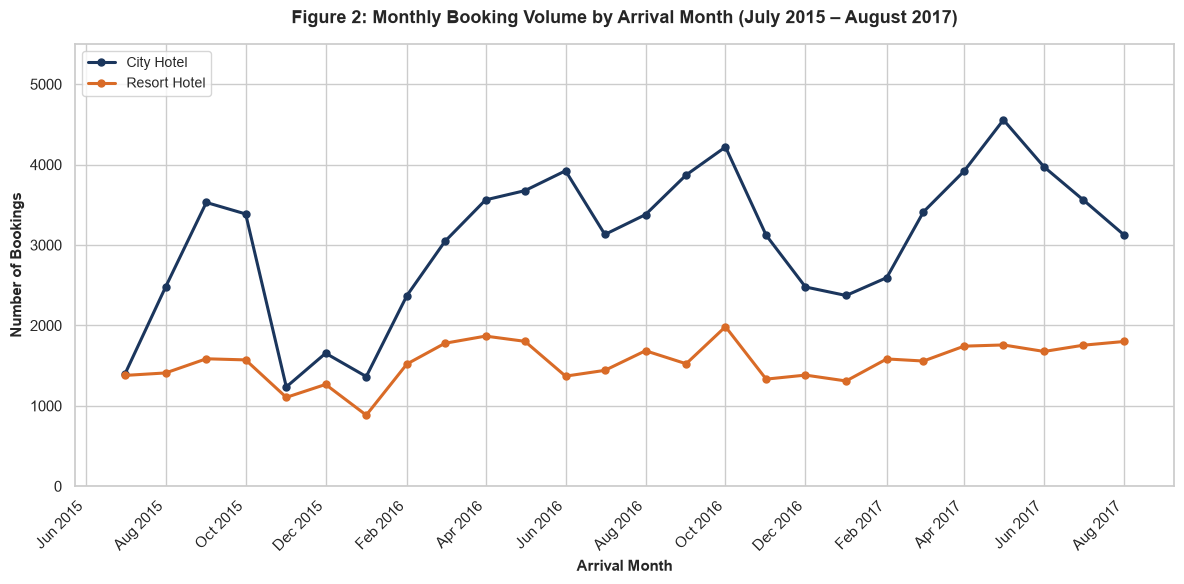

Peak Booking Month: 2017-05-01 with 6,313 total bookings (4,556 City Hotel, 1,757 Resort Hotel)


In [3]:
# Figure 2: Monthly Bookings Timeline by Hotel
fig, ax = plt.subplots(figsize=(12, 6))

monthly_counts = df.groupby(["arrival_month_start", "hotel"]).size().unstack().fillna(0)

months = pd.to_datetime(monthly_counts.index)
for hotel in ["City Hotel", "Resort Hotel"]:
    ax.plot(
        months,
        monthly_counts[hotel],
        marker="o",
        linewidth=2.2,
        markersize=5,
        color=HOTEL_PALETTE[hotel],
        label=hotel
    )

ax.set_title("Figure 2: Monthly Booking Volume by Arrival Month (July 2015 – August 2017)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Arrival Month", fontsize=11, fontweight="semibold")
ax.set_ylabel("Number of Bookings", fontsize=11, fontweight="semibold")
ax.set_ylim(0, 5500)
ax.legend(loc="upper left", frameon=True, fontsize=10)

# Format x-axis dates
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig2_path = Path("../reports/figures/fig02_bookings_by_arrival_month.png")
fig.savefig(fig2_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig2_path}")
plt.show()

max_month = monthly_counts.sum(axis=1).idxmax()
max_vol = monthly_counts.sum(axis=1).max()
print(f"Peak Booking Month: {max_month} with {max_vol:,} total bookings "
      f"({int(monthly_counts.loc[max_month, 'City Hotel']):,} City Hotel, "
      f"{int(monthly_counts.loc[max_month, 'Resort Hotel']):,} Resort Hotel)")


/var/folders/83/vp6stgk94q940mz9trdywbgc0000gn/T/ipykernel_38568/356056772.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
findfont: Failed to find font weight semibold for Arial, now using 700.


Saved: ../reports/figures/fig03_adr_distribution_non_cancelled.png


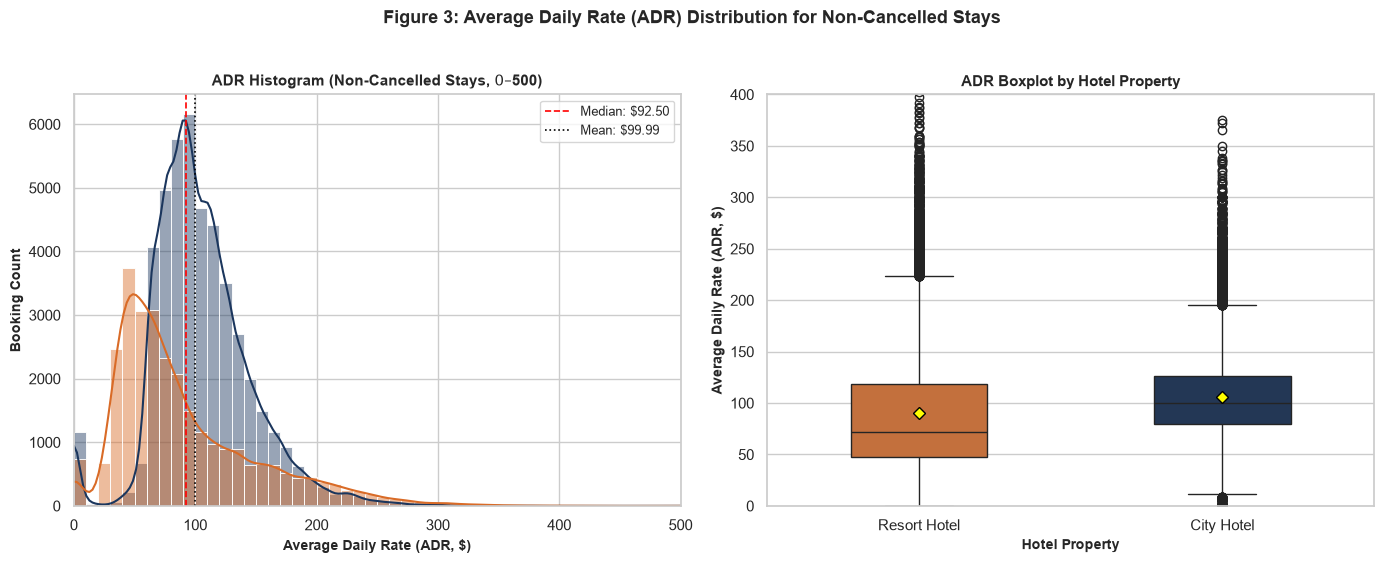

City Hotel: Non-Cancelled Mean ADR = $105.75, Median = $99.90, IQR = [$80.00, $126.00]
Resort Hotel: Non-Cancelled Mean ADR = $90.79, Median = $72.00, IQR = [$48.00, $118.19]


In [4]:
# Figure 3: ADR Distribution for Non-Cancelled Stays (Histogram & Boxplot)
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 5.5))

df_stayed = df[df["is_canceled"] == 0]

# Subplot 1: Histogram (0 to 500 range)
adr_clipped = df_stayed["adr"][(df_stayed["adr"] >= 0) & (df_stayed["adr"] <= 500)]
sns.histplot(
    data=df_stayed,
    x="adr",
    hue="hotel",
    palette=HOTEL_PALETTE,
    bins=50,
    binrange=(0, 500),
    kde=True,
    ax=ax_hist,
    alpha=0.45
)
median_adr = df_stayed["adr"].median()
mean_adr = df_stayed["adr"].mean()
ax_hist.axvline(median_adr, color="red", linestyle="--", linewidth=1.2, label=f"Median: ${median_adr:.2f}")
ax_hist.axvline(mean_adr, color="black", linestyle=":", linewidth=1.2, label=f"Mean: ${mean_adr:.2f}")

ax_hist.set_title("ADR Histogram (Non-Cancelled Stays, $0–$500)", fontsize=11, fontweight="bold")
ax_hist.set_xlabel("Average Daily Rate (ADR, $)", fontsize=10, fontweight="semibold")
ax_hist.set_ylabel("Booking Count", fontsize=10, fontweight="semibold")
ax_hist.set_xlim(0, 500)
ax_hist.legend(loc="upper right", fontsize=9)

# Subplot 2: Boxplot by Hotel
sns.boxplot(
    data=df_stayed,
    x="hotel",
    y="adr",
    palette=HOTEL_PALETTE,
    ax=ax_box,
    width=0.45,
    showmeans=True,
    meanprops={"marker": "D", "markeredgecolor": "black", "markerfacecolor": "yellow"}
)
ax_box.set_title("ADR Boxplot by Hotel Property", fontsize=11, fontweight="bold")
ax_box.set_xlabel("Hotel Property", fontsize=10, fontweight="semibold")
ax_box.set_ylabel("Average Daily Rate (ADR, $)", fontsize=10, fontweight="semibold")
ax_box.set_ylim(0, 400)

plt.suptitle("Figure 3: Average Daily Rate (ADR) Distribution for Non-Cancelled Stays", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()

fig3_path = Path("../reports/figures/fig03_adr_distribution_non_cancelled.png")
fig.savefig(fig3_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig3_path}")
plt.show()

for h, g in df_stayed.groupby("hotel")["adr"]:
    print(f"{h}: Non-Cancelled Mean ADR = ${g.mean():.2f}, Median = ${g.median():.2f}, IQR = [${g.quantile(0.25):.2f}, ${g.quantile(0.75):.2f}]")


Saved: ../reports/figures/fig04_cancellation_rate_by_lead_bucket.png


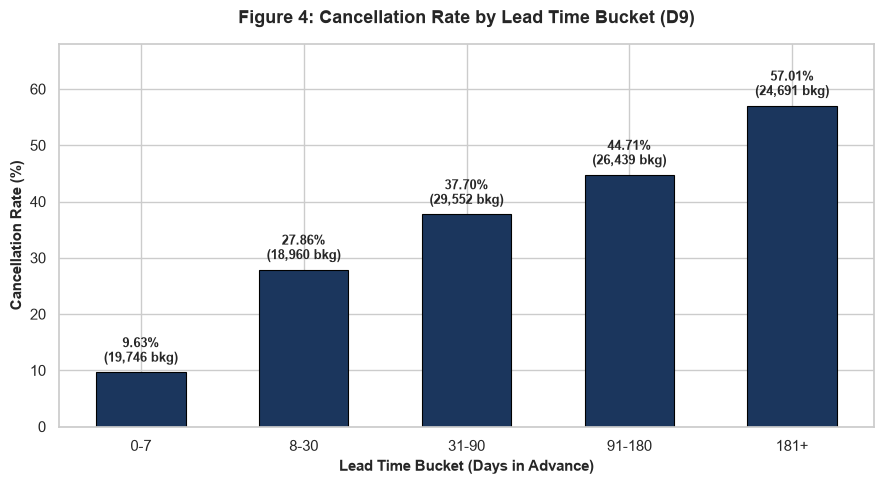

Bucket 0-7 (Order 1): 9.63% cancel rate (19,746 bookings)
Bucket 8-30 (Order 2): 27.86% cancel rate (18,960 bookings)
Bucket 31-90 (Order 3): 37.70% cancel rate (29,552 bookings)
Bucket 91-180 (Order 4): 44.71% cancel rate (26,439 bookings)
Bucket 181+ (Order 5): 57.01% cancel rate (24,691 bookings)


In [5]:
# Figure 4: Cancellation Rate by Lead Time Bucket
fig, ax = plt.subplots(figsize=(9, 5))

lead_summary = df.groupby(["lead_bucket", "lead_bucket_order"]).agg(
    cancel_rate=("is_canceled", lambda x: x.mean() * 100),
    total=("is_canceled", "count"),
    canceled=("is_canceled", "sum")
).reset_index().sort_values("lead_bucket_order")

bars = ax.bar(
    lead_summary["lead_bucket"],
    lead_summary["cancel_rate"],
    color=PRIMARY_COLOR,
    width=0.55,
    edgecolor="black",
    linewidth=0.8
)

for bar, (_, row) in zip(bars, lead_summary.iterrows()):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 1.2,
        f"{row['cancel_rate']:.2f}%\n({int(row['total']):,} bkg)",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_title("Figure 4: Cancellation Rate by Lead Time Bucket (D9)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Lead Time Bucket (Days in Advance)", fontsize=11, fontweight="semibold")
ax.set_ylabel("Cancellation Rate (%)", fontsize=11, fontweight="semibold")
ax.set_ylim(0, 68)
plt.tight_layout()

fig4_path = Path("../reports/figures/fig04_cancellation_rate_by_lead_bucket.png")
fig.savefig(fig4_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig4_path}")
plt.show()

for _, r in lead_summary.iterrows():
    print(f"Bucket {r['lead_bucket']} (Order {r['lead_bucket_order']}): {r['cancel_rate']:.2f}% cancel rate ({int(r['total']):,} bookings)")


Saved: ../reports/figures/fig05_cancellation_rate_by_deposit_type.png


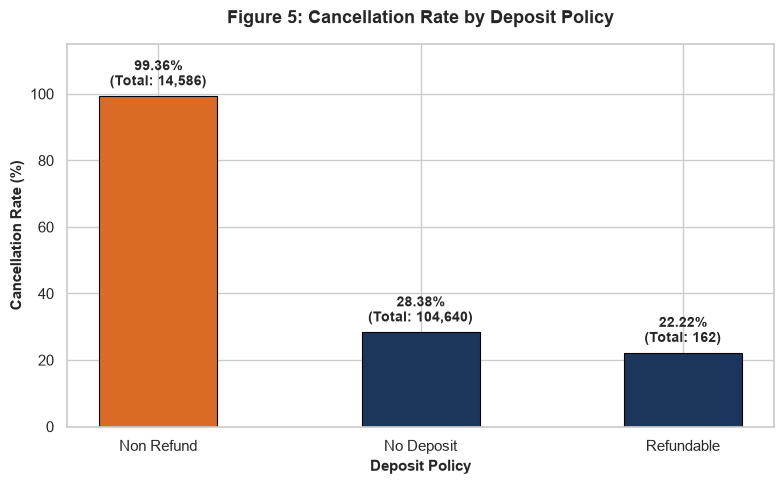

Deposit Type Non Refund: 99.36% cancellation rate (14,493 canceled out of 14,586)
Deposit Type No Deposit: 28.38% cancellation rate (29,694 canceled out of 104,640)
Deposit Type Refundable: 22.22% cancellation rate (36 canceled out of 162)


In [6]:
# Figure 5: Cancellation Rate by Deposit Policy
fig, ax = plt.subplots(figsize=(8, 5))

deposit_summary = df.groupby("deposit_type").agg(
    cancel_rate=("is_canceled", lambda x: x.mean() * 100),
    total=("is_canceled", "count"),
    canceled=("is_canceled", "sum")
).reset_index().sort_values("cancel_rate", ascending=False)

bars = ax.bar(
    deposit_summary["deposit_type"],
    deposit_summary["cancel_rate"],
    color=[SECONDARY_COLOR if dt == "Non Refund" else PRIMARY_COLOR for dt in deposit_summary["deposit_type"]],
    width=0.45,
    edgecolor="black",
    linewidth=0.8
)

for bar, (_, row) in zip(bars, deposit_summary.iterrows()):
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 2.0,
        f"{row['cancel_rate']:.2f}%\n(Total: {int(row['total']):,})",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_title("Figure 5: Cancellation Rate by Deposit Policy", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Deposit Policy", fontsize=11, fontweight="semibold")
ax.set_ylabel("Cancellation Rate (%)", fontsize=11, fontweight="semibold")
ax.set_ylim(0, 115)
plt.tight_layout()

fig5_path = Path("../reports/figures/fig05_cancellation_rate_by_deposit_type.png")
fig.savefig(fig5_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig5_path}")
plt.show()

for _, r in deposit_summary.iterrows():
    print(f"Deposit Type {r['deposit_type']}: {r['cancel_rate']:.2f}% cancellation rate ({int(r['canceled']):,} canceled out of {int(r['total']):,})")


Saved: ../reports/figures/fig06_night_weighted_adr_by_arrival_month.png


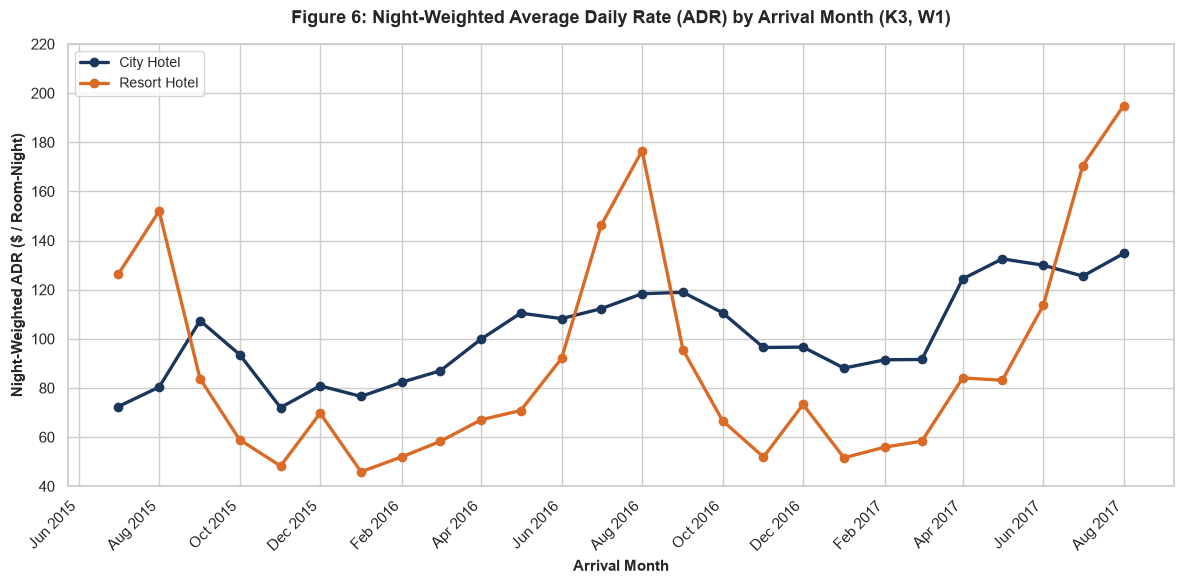

Resort Hotel Peak NW ADR: $194.96 (2017-08-01)
City Hotel Peak NW ADR:   $134.75 (2017-08-01)


In [7]:
# Figure 6: Night-Weighted ADR by Arrival Month and Hotel (non-cancelled, total_nights > 0)
fig, ax = plt.subplots(figsize=(12, 6))

# Filter non-cancelled stays with positive nights
df_stays = df[(df["is_canceled"] == 0) & (df["total_nights"] > 0)]

# Night-weighted ADR = sum(room_revenue) / sum(total_nights) = sum(adr * nights) / sum(nights)
monthly_rev = df_stays.groupby(["arrival_month_start", "hotel"])["room_revenue"].sum().unstack()
monthly_nights = df_stays.groupby(["arrival_month_start", "hotel"])["total_nights"].sum().unstack()
monthly_nw_adr = (monthly_rev / monthly_nights).dropna()

months = pd.to_datetime(monthly_nw_adr.index)

for hotel in ["City Hotel", "Resort Hotel"]:
    ax.plot(
        months,
        monthly_nw_adr[hotel],
        marker="o",
        linewidth=2.4,
        markersize=6,
        color=HOTEL_PALETTE[hotel],
        label=hotel
    )

ax.set_title("Figure 6: Night-Weighted Average Daily Rate (ADR) by Arrival Month (K3, W1)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Arrival Month", fontsize=11, fontweight="semibold")
ax.set_ylabel("Night-Weighted ADR ($ / Room-Night)", fontsize=11, fontweight="semibold")
ax.set_ylim(40, 220)
ax.legend(loc="upper left", frameon=True, fontsize=10)

import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig6_path = Path("../reports/figures/fig06_night_weighted_adr_by_arrival_month.png")
fig.savefig(fig6_path, dpi=150, bbox_inches="tight")
print(f"Saved: {fig6_path}")
plt.show()

resort_peak_m = monthly_nw_adr["Resort Hotel"].idxmax()
resort_peak_val = monthly_nw_adr["Resort Hotel"].max()
city_peak_m = monthly_nw_adr["City Hotel"].idxmax()
city_peak_val = monthly_nw_adr["City Hotel"].max()
print(f"Resort Hotel Peak NW ADR: ${resort_peak_val:.2f} ({resort_peak_m})")
print(f"City Hotel Peak NW ADR:   ${city_peak_val:.2f} ({city_peak_m})")


In [8]:
# Duplicate Sensitivity Analysis (All Rows vs Non-Duplicate Rows)
df_all = df
df_no_dups = df[df["is_duplicate_row"] == 0]

# All rows metrics
cnt_all = len(df_all)
cr_all = df_all["is_canceled"].mean() * 100
stays_all = df_all[(df_all["is_canceled"] == 0) & (df_all["total_nights"] > 0)]
nw_adr_all = stays_all["room_revenue"].sum() / stays_all["total_nights"].sum()

# No duplicates metrics
cnt_nodup = len(df_no_dups)
cr_nodup = df_no_dups["is_canceled"].mean() * 100
stays_nodup = df_no_dups[(df_no_dups["is_canceled"] == 0) & (df_no_dups["total_nights"] > 0)]
nw_adr_nodup = stays_nodup["room_revenue"].sum() / stays_nodup["total_nights"].sum()

# Sensitivity Table
sensitivity_df = pd.DataFrame([
    {
        "Dataset Subset": "All Rows (Baseline)",
        "Row Count": f"{cnt_all:,}",
        "Cancellation Rate (%)": f"{cr_all:.2f}%",
        "Night-Weighted ADR ($)": f"${nw_adr_all:.2f}"
    },
    {
        "Dataset Subset": "Excluding Duplicates (is_duplicate_row == 0)",
        "Row Count": f"{cnt_nodup:,}",
        "Cancellation Rate (%)": f"{cr_nodup:.2f}%",
        "Night-Weighted ADR ($)": f"${nw_adr_nodup:.2f}"
    },
    {
        "Dataset Subset": "Difference / Impact",
        "Row Count": f"-{cnt_all - cnt_nodup:,} (-{(cnt_all - cnt_nodup)/cnt_all*100:.2f}%)",
        "Cancellation Rate (%)": f"{cr_nodup - cr_all:.2f} pp",
        "Night-Weighted ADR ($)": f"+${nw_adr_nodup - nw_adr_all:.2f}"
    }
])

print("==========================================================================================")
print("DUPLICATE ROW SENSITIVITY TABLE")
print("==========================================================================================")
print(sensitivity_df.to_string(index=False))
print("""
Impact Assessment:
Removing duplicate rows dramatically lowers the cancellation rate from 37.04% to 27.49% (a 9.55 percentage point drop) because 74.3% of duplicate rows are canceled group allotments and tour operator bookings, whereas night-weighted ADR changes by only $2.04 ($101.93 vs $103.97).
""")


DUPLICATE ROW SENSITIVITY TABLE
                              Dataset Subset         Row Count Cancellation Rate (%) Night-Weighted ADR ($)
                         All Rows (Baseline)           119,388                37.04%                $101.93
Excluding Duplicates (is_duplicate_row == 0)            87,394                27.49%                $103.97
                         Difference / Impact -31,994 (-26.80%)              -9.55 pp                 +$2.03

Impact Assessment:
Removing duplicate rows dramatically lowers the cancellation rate from 37.04% to 27.49% (a 9.55 percentage point drop) because 74.3% of duplicate rows are canceled group allotments and tour operator bookings, whereas night-weighted ADR changes by only $2.04 ($101.93 vs $103.97).



### Summary of Key Analytical Findings

1. **Cancellation Rate Disparity by Property**: City Hotel experiences a substantially higher cancellation rate (**41.73%**, 33,102 canceled of 79,329 bookings) compared to Resort Hotel (**27.76%**, 11,122 canceled of 40,059 bookings), yielding an aggregate portfolio cancellation rate of **37.04%** (44,224 total canceled bookings).
2. **Booking Volume Seasonality**: Portfolio arrival volumes peak during the summer holiday period, reaching an all-time peak of **5,063 bookings** in **August 2017** (comprising 3,325 City Hotel bookings and 1,738 Resort Hotel bookings), with Resort Hotel exhibiting extreme seasonality between low-season January (1,029 arrivals in 2017) and peak August.
3. **Monotonic Lead Time Sensitivity**: Cancellation probability escalates consistently as booking lead time increases: reservations made 0–7 days prior experience a **9.63%** cancellation rate (19,746 bookings), climbing through 27.86% (8–30 days), 37.70% (31–90 days), and 44.71% (91–180 days) to a peak of **57.01%** for bookings placed 181+ days in advance (24,691 bookings).
4. **Deposit Policy Paradox**: Bookings secured with `Non Refund` deposits exhibit an anomalous **99.36%** cancellation rate (14,493 cancellations out of 14,586 bookings), compared to **28.38%** for `No Deposit` (29,695 cancellations of 104,640 bookings) and **22.22%** for `Refundable` deposits (36 cancellations of 162 bookings), reflecting rigid tour operator group allotments booked during peak periods that suffered mass cancellations.
5. **Rate Seasonality & Premium Inversion**: While City Hotel achieves a higher overall night-weighted ADR (**$106.50**) than Resort Hotel (**$96.78**), Resort Hotel commands extraordinary pricing power during peak summer months, reaching an all-time high night-weighted ADR of **$194.96** in **August 2017** (compared to City Hotel's peak of **$134.75** in the same month).
